# Anomaly detection - Identifiying network attack 

We start by loading all necessary libraries and helper functions

In [1]:
# Load libraries and helper functions
%run helpers.py

## The overall dataset

The data is based on the [KDD-CUP 1999 challenge](http://kdd.ics.uci.edu/databases/kddcup99/kddcup99.html) on network intrusion detection. A description of the original task can be found [here](http://kdd.ics.uci.edu/databases/kddcup99/task.html). The data provided for this workshop has been adapted from the [NSL-KDD version](https://www.kaggle.com/hassan06/nslkdd).

### Anomaly detection - the idea

Anomaly detection can be treated as a supervised classification task. However this approach struggles when the portion of anomalies (here network attacks) is small. Instead we showcase an approach using [Isolation Forests](https://www.youtube.com/watch?v=RyFQXQf4w4w). 

You will be able to select the size of training dataset and vary its contamination rate, including a dataset without any anomalies. The model is then trained on this dataset, used to predict anomalies on a separate test set and evaluate the performance.


## Create the training dataset

We start by creating a data set on which we will train our anomaly detector.  
We can choose the **size of the data set** as well as the **ratio of samples that are attacks** (ratio of contamination)  
If you set the ratio to 0, the dataset will be clean and contains no attacks. The model can still learn!

The number of samples should be a number between 100 and 80819.  

The ratio should be a number between 0 and 0.5.

In [2]:
# Set the values for size and ratio
size = 10000
ratio = 0

In [8]:
dataset = create_dataset(size, ratio)

Your dataset has been created.
It contains 10000 samples, of which 0 are malicious attacks.
The rest is normal traffic.


<div class="alert alert-info">
<h3>Important</h3>

<p>When training the model we will only pass it the features of the samples. The model will never see the class labels, and hence can not gain any feedback from comparing them against its own 'decisions'.<br>
We call this <b>unsupervised learning</b>.</p>
    
<p>However, here we will use the class labels to gain further insight by analysing and visualising the data and later for evaluating our model in some more detail.</p>
</div>

## Explore the training data and visualise 1000 samples

1) We look at the distribution of different attack types in our training data.

2) We use a TSNE-plot to explore part of our training data.  
The TSNE-plot reduces our 51 features to 2 dimensions by trying to represent local structures faithfully.

Your training set has the following composition:


,frequency
class,
normal,10000


Plotting 1000 samples of the training data


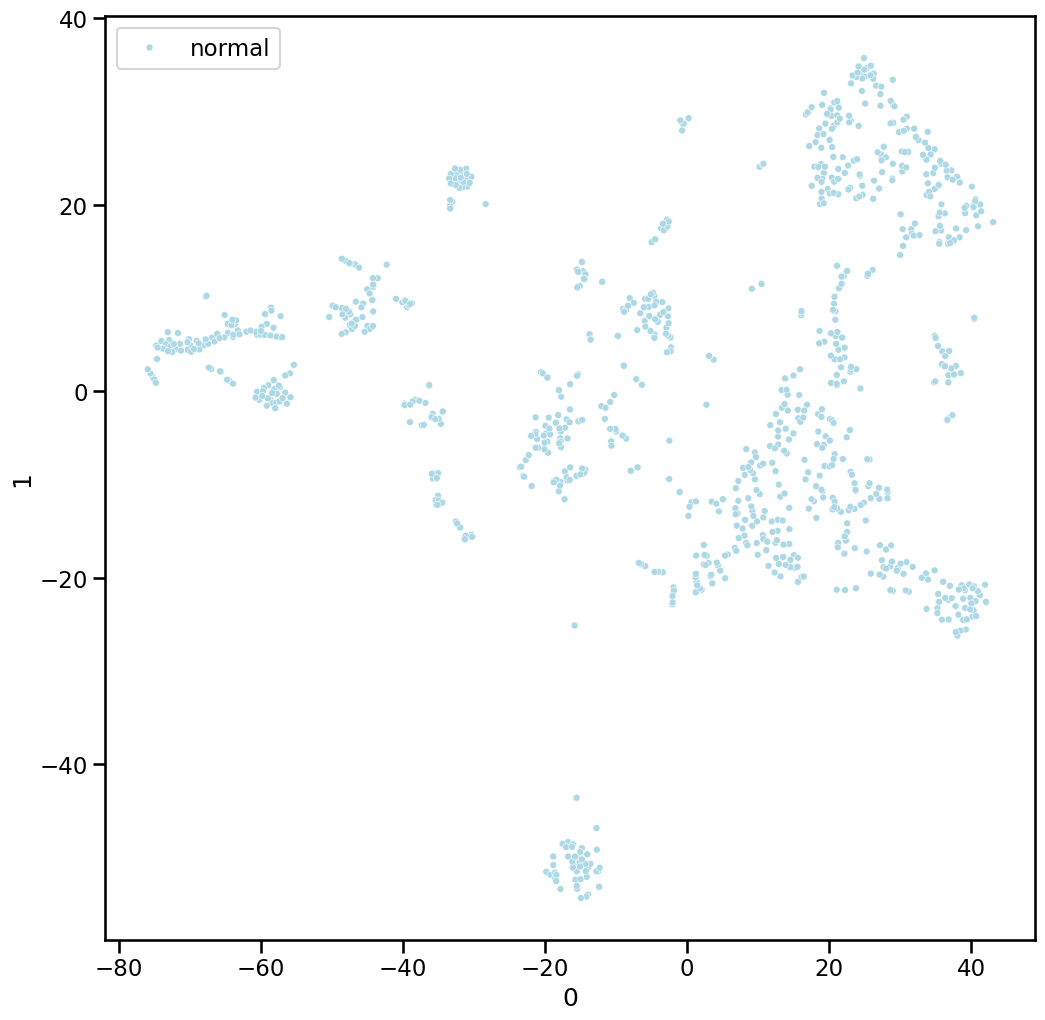

In [4]:
explore_and_visualise_training_data(dataset)

<div class="alert alert-success">
<h2>Questions - Part 1</h2>
    
The purpose of these questions is to create some expectations of the performance of our model and the problems it might encounter.

Note: <i>These questions only make sense for training data that has been contaminated</i>.
    
What do you observe about <br>
<ol>
<li> the <b>frequency of the different malware types</b> in our data set? </li>
<li> the <b>distribution of the different malware types</b> in the TSNE plot? </li>
<li> the <b>distribution of the normal samples</b> in the TSNE plot? </li>
<li><b>Which types of malware</b> do you expect to be <b>easy to find</b>, and which ones would be <b>harder to detect</b>? </li>
</ol>
</div>

#### Give your observation here:

My observations (for the case 10000 samples with 10% malware):

<ol>
<li> The different malware classes are not evenly distributed. Pod and guess_psswrd are very rare while neptune, ipsweep and satan are fairly common.</li>
<li> Some malware types are forming their own disjoint clusters (here neptune, smurf and ipsweep) <br>
    Some samples are very close to normal samples (here satan, warezclient).</li>
<li> The normal samples form multiple clusters, but there also several that are quite isolated int his plot. These could lead to false alarms. </li>
<li> Malware that is close to many normal samples will be harder to find. Common malware forming clusters might be misinterpreted as sufficiently common and thus as normal.</li>
</ol>

# Anomaly detection - the model

## Training our model

The **expected_contamination** is the portion of anomalies (attacks) that we expect in the real-life test set. This value is independent of the *portion of attacks* we chose to place in the training data.

**PCA (Principal Component Analysis)** transforms our data by trying to identify the directions (= combinations of features) in the data in which the data varies most. This might help the Isolation Forest algorithm to isolate anomalies faster, or it might not. 

In [5]:
model, dataset = build_anomaly_detector(
    dataset,
    expected_contamination=0.1,      # value between 0 and 0.5
    with_PCA = False)                # True / False

## Evaluating the performance

1) We take at look at the scores assigned by the **decision function** to our different samples. Samples with negative scores are marked as anomalies.

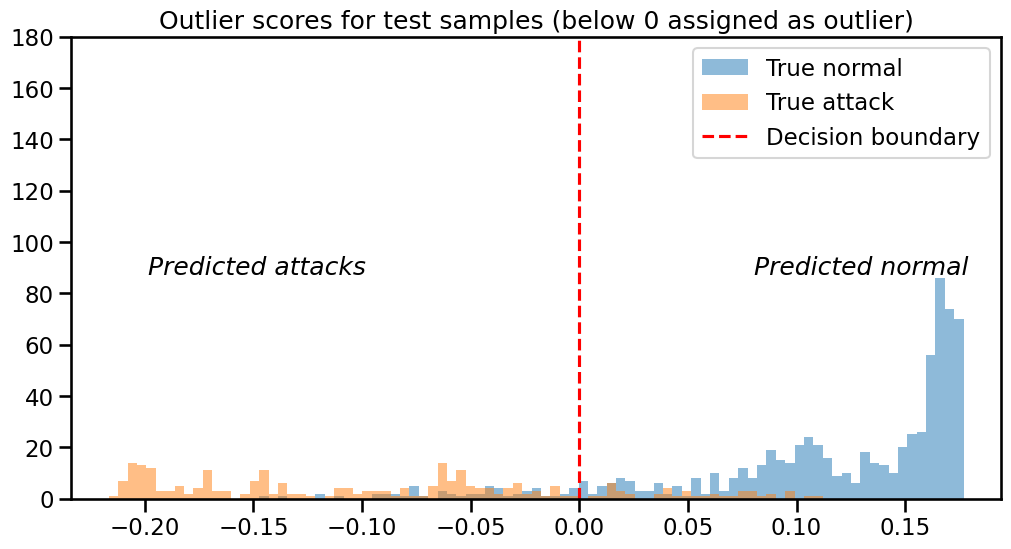

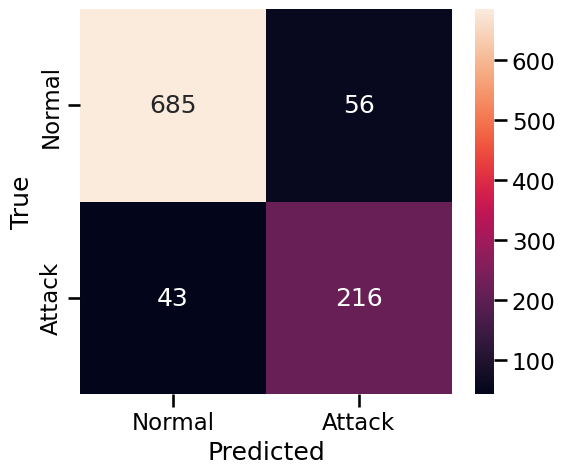

Summary report:
Attacks identified correctly (true positive): 216  of  259 ( 83.4 %)
Attacks missed (false negative): 43  of  259 ( 16.6 %)
False alarms (false positive): 56  of 741 ( 7.6 %)
Total number of misclassified samples: 99


In [6]:
evaluate_model(dataset, model)

<div class="alert alert-success">
<h2>Questions - Part 2</h2>

<p>Let's take a look at the results above. First take a look at everything, then try to answer the following questions:</p>

<ol>
<li>  In the first plot how many blue samples are found on the left hand side?</li>
<li>  In the first plot how many orange samples are found on the right hand side?</li>
<li>  Which of these two mispredictions are worse for us?</li>
</ol>

</div>

#### Give your observation here:

My observations (for the case 10000 samples with 10% malware):

<ol>
<li>  We are looking for normal samples labelled as malware, i.e. false attacks (top right square). Thus there are 33.</li>
<li>  We are looking for malware labelled as normal samples, i.e. missed attacks (bottom left square). Thus there are 107.</li>
<li>  The more costly mispredictions are the false attacks (irrespective of their precise numbers)</li>
</ol>


## Taking a more detailed look at our performance

1) We look at the performance of our predictions at the level of individual attack types.

2) We locate the misclassified samples (triangles, colour gives true label) inside our test set.

Detailed report:


,present,missed,pct_missed
attack_detail,,,
back,11,10,90.9
guess_passwd,1,0,0.0
ipsweep,40,0,0.0
neptune,68,0,0.0
nmap,16,2,12.5
normal,741,56,7.6
pod,2,1,50.0
portsweep,32,0,0.0
satan,40,8,20.0


Plotting 1000 samples of the test data




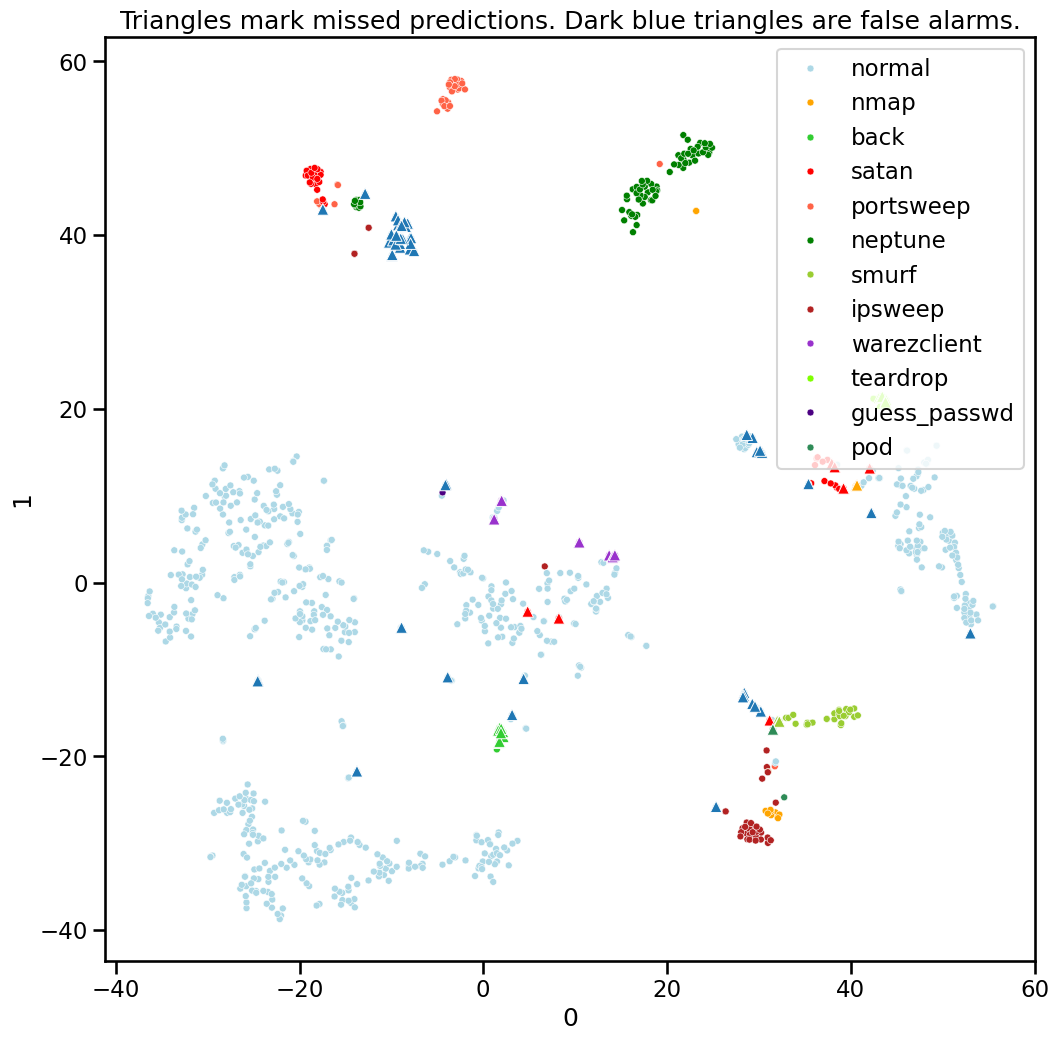

In [7]:
detailed_evaluation(dataset, model)

<div class="alert alert-success">
<h2>Questions - Part 3</h2>

Let's compare our expectations build from Part 1 with the actual performance. 

<ol>
<li>  For which types of malware did our model perform well, and for which did it do poorly?</li>
<li>  Does this match the observations and expectations we made in Part 1?</li>
</ol>   
<p>Dark blue triangles indicate false alarms, i.e. normal behaviour that was predicted as malware. <br>
The other triangles indicate malware that was not detected.</p>

<ol start="3">
<li>  What do you observe about the location of the false alarms?</li>
<li>  What do you observe about the location of undetected malware?</li>
<li>  Does this match the observations and expectations we made in Part 1?</li>
</ol>

</div>

#### Give your observation here:

My observations:

<ol>
<li>  Our model perform very well on neptune and portsweep, as expected it struggled with rarer class. Surprisingly it also struggled a lot with ipsweep.</li>
<li>  To be fair only in parts.</li>
<li>  Some of the false alarms are quite isolated, which might have raised the flag. Others are close to other malware.</li>
<li>  Some missed warezclient and satan samples are hiding amongst the normal samples. But other missed attacks are forming big groups.</li>
<li>  It appears that some denser groups in the training data were considered as normal by the model.</li>
</ol> 

# Additional tasks

Unless specified all observations below are based on 10000 samples and 10% malwaree in the training data.

<div class="alert alert-success">
<h3>Task 1</h3>

Let's vary the `expected_contamination` parameter which is used by the model to make decisions. <br>     You only need to run cells in section 2 "Anomaly detection - the model" <br>    
What do you observe about distribution of the outlier scores and the position of the decision boundary?<br>
</div>

#### Give your observation here:

Setting `expected_contamination` to 0.2 shifts the decision further to the right, thus resulting in more false alarms but far fewer missed attacks. In particular, nmap, smurf and ipsweep faired better.

<div class="alert alert-success">
<h3>Task 2</h3>

You need to rerun the entire notebook here. <br>
1. Vary the size of your training data.<br> 
2. Vary the portion of attacks in your training data.<br>
3. In particular let's see how the model performs when we only use totally clean training data without any anomalies.<br>
</div>

#### Give your observation here:

Training on 10000 but with 0% malware gives better results (43 missed attacks). Neptune, ipsweep and portsweep were detected perfectly. Smurf and nmap were quite good to.

<div class="alert alert-success">
<h3>Task 3</h3>
    
Let's see whether using PCA before training our model helps. <br> 
You only need to run cells in  section 2 "Anomaly detection - the model"<br>
    
Set `with_PCA = True` inside the `build_anomaly_detector`. <br>
</div>

#### Give your observation here:

In this particular case it made things even worse (150 missed attacks). In particular neptune failed.

On 10000 clean samples it made an improvement (31 missed attacks)